In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_lter.csv
/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_size.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns

In [3]:
import os

os.listdir("/kaggle/input")

['datasets']

In [4]:
os.listdir("/kaggle/input/datasets")

['parulpandey']

In [5]:
os.listdir("/kaggle/input/datasets/parulpandey")

['palmer-archipelago-antarctica-penguin-data']

In [6]:
os.listdir("/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data")

['penguins_lter.csv', 'penguins_size.csv']

In [7]:
df = pd.read_csv(
    "/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_size.csv"
)

df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [8]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (344, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [9]:
df.isnull().sum()

species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

In [10]:
df["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [11]:
features = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

target = "species"

df_clean = df[features + [target]].copy()

df_clean.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species
0,39.1,18.7,181.0,3750.0,Adelie
1,39.5,17.4,186.0,3800.0,Adelie
2,40.3,18.0,195.0,3250.0,Adelie
3,NaN,NaN,NaN,NaN,Adelie
4,36.7,19.3,193.0,3450.0,Adelie


In [12]:
df_clean.isnull().sum()

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
species              0
dtype: int64

In [13]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df_clean["species"] = le.fit_transform(df_clean["species"])

print("Classes:", le.classes_)
print(df_clean["species"].value_counts())

Classes: ['Adelie' 'Chinstrap' 'Gentoo']
species
0    152
2    124
1     68
Name: count, dtype: int64


In [14]:
X = df_clean[features].values

y = df_clean["species"].values

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (344, 4)
y Shape: (344,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (275, 4)
X_test: (69, 4)
y_train: (275,)
y_test: (69,)


In [16]:

# Handle missing values using training data medians only

train_medians = np.nanmedian(X_train, axis=0)

X_train = np.where(np.isnan(X_train), train_medians, X_train)
X_test = np.where(np.isnan(X_test), train_medians, X_test)

print("Missing values in X_train:", np.isnan(X_train).sum())
print("Missing values in X_test:", np.isnan(X_test).sum())


Missing values in X_train: 0
Missing values in X_test: 0


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [18]:
print("Training Mean:", X_train.mean(axis=0))
print("Training Std:", X_train.std(axis=0))

Training Mean: [-2.77030923e-15  5.63428092e-15  3.73438654e-16  1.00929366e-16]
Training Std: [1. 1. 1. 1.]


In [19]:
def rbf_kernel(X1, X2, gamma=0.25):
    X1_sq = np.sum(X1**2, axis=1).reshape(-1, 1)
    X2_sq = np.sum(X2**2, axis=1).reshape(1, -1)

    distances = X1_sq + X2_sq - 2 * X1 @ X2.T
    distances = np.maximum(distances, 0)

    return np.exp(-gamma * distances)

In [20]:
gamma = 1 / X_train.shape[1]

K_train = rbf_kernel(X_train, X_train, gamma)

K_test = rbf_kernel(X_test, X_train, gamma)

print("K_train Shape:", K_train.shape)
print("K_test Shape:", K_test.shape)

K_train Shape: (275, 275)
K_test Shape: (69, 275)


In [21]:
classes = np.unique(y_train)

Y_train = np.where(
    y_train.reshape(-1, 1) == classes.reshape(1, -1),
    1,
    -1
)

print("Classes:", classes)
print("Y_train Shape:", Y_train.shape)
print("First 5 labels:")
print(Y_train[:5])

Classes: [0 1 2]
Y_train Shape: (275, 3)
First 5 labels:
[[ 1 -1 -1]
 [ 1 -1 -1]
 [ 1 -1 -1]
 [-1 -1  1]
 [-1 -1  1]]


In [22]:
n_samples = X_train.shape[0]
n_classes = len(classes)

alpha = np.zeros((n_samples, n_classes))
bias = np.zeros(n_classes)

learning_rate = 0.01
epochs = 500
lambda_reg = 0.01

momentum = 0.9

velocity_alpha = np.zeros_like(alpha)
velocity_bias = np.zeros_like(bias)

print("Alpha Shape:", alpha.shape)
print("Bias Shape:", bias.shape)
print("Learning Rate:", learning_rate)
print("Epochs:", epochs)
print("Momentum:", momentum)

Alpha Shape: (275, 3)
Bias Shape: (3,)
Learning Rate: 0.01
Epochs: 500
Momentum: 0.9


In [23]:
def predict_scores(K, alpha, bias):
    return K @ alpha + bias

In [24]:
def calculate_loss(K, Y, alpha, bias, lambda_reg):

    scores = predict_scores(K, alpha, bias)

    margins = 1 - Y * scores

    hinge_loss = np.maximum(0, margins).mean()

    regularization = 0.5 * lambda_reg * np.sum(alpha * (K @ alpha))

    total_loss = hinge_loss + regularization

    return total_loss

In [25]:
def calculate_gradients(K, Y, alpha, bias, lambda_reg):

    scores = predict_scores(K, alpha, bias)

    margins = 1 - Y * scores

    active = (margins > 0).astype(float)

    grad_alpha = -(K.T @ (Y * active)) / Y.size
    grad_alpha += lambda_reg * (K @ alpha)

    grad_bias = -(Y * active).sum(axis=0) / Y.size

    return grad_alpha, grad_bias

In [26]:
loss_history = []

for epoch in range(epochs):

    grad_alpha, grad_bias = calculate_gradients(
        K_train, Y_train, alpha, bias, lambda_reg
    )

    velocity_alpha = (
        momentum * velocity_alpha
        - learning_rate * grad_alpha
    )

    velocity_bias = (
        momentum * velocity_bias
        - learning_rate * grad_bias
    )

    alpha += velocity_alpha
    bias += velocity_bias

    loss = calculate_loss(
        K_train, Y_train, alpha, bias, lambda_reg
    )

    loss_history.append(loss)

print("Training Completed!")
print("Final Loss:", loss_history[-1])

Training Completed!
Final Loss: 0.17928827793469987


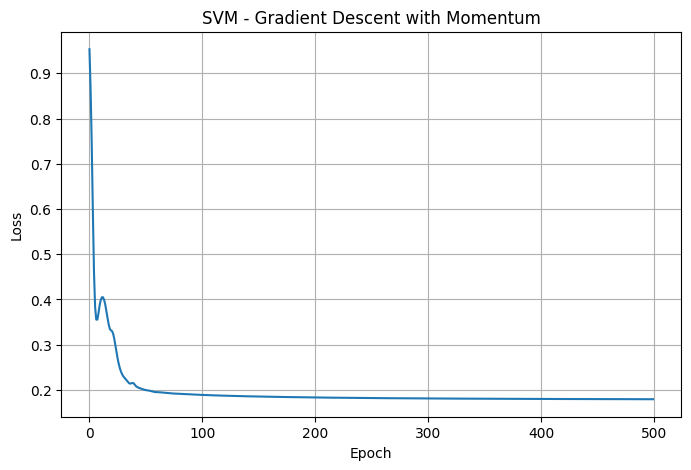

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("SVM - Gradient Descent with Momentum")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.grid(True)
plt.show()

In [28]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [29]:
y_scores = predict_scores(K_test, alpha, bias)

y_pred = classes[np.argmax(y_scores, axis=1)]

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

Test Accuracy: 0.9855072463768116
Test Accuracy (%): 98.55072463768117


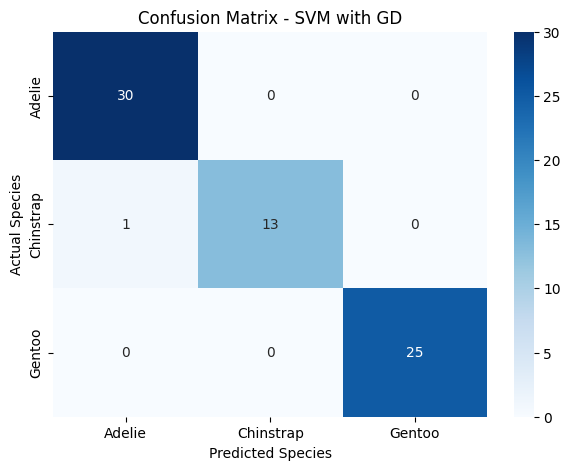

In [30]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("Confusion Matrix - SVM with GD")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

In [31]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_
))

              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.98        30
   Chinstrap       1.00      0.93      0.96        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.99      0.98      0.98        69
weighted avg       0.99      0.99      0.99        69

